# Étape 7 : ModernBERT sur le document entier

Troisième approche : utiliser un modèle qui accepte des textes longs (jusqu'à 8 192 tokens) pour lire chaque compte rendu en entier, sans découpage et sans regex.

On utilise `jhu-clsp/mmBERT-base`, un modèle multilingue basé sur l'architecture ModernBERT. D'autres checkpoints peuvent être testés en changeant `MODEL_CHECKPOINT` : `almanach/moderncamembert-base` (français) ou `answerdotai/ModernBERT-base` (anglais).

Pour que l'entraînement tienne sur un T4 : fp16, gradient checkpointing, batch de 2 avec accumulation de gradient, et `reference_compile=False` car `torch.compile` pose problème sur ce GPU.

## Installation et configuration

In [4]:
%pip install -q "transformers>=4.48" "accelerate>=0.34" sentencepiece protobuf pyarrow

In [ ]:
import gc, json, os, re, sys, time, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

import transformers
from transformers import (AutoConfig, AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup, set_seed)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report, cohen_kappa_score,
                             confusion_matrix, f1_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| transformers", transformers.__version__, "| device :", DEVICE)
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("Pas de GPU")

# calcul en fp16 sur GPU pour aller plus vite et prendre moins de mémoire
USE_AMP = DEVICE == "cuda"

torch 2.14.1+cu130 | transformers 5.22.1 | device : cuda
Tesla T4


In [6]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/stage_m2"
else:
    BASE_DIR = "."

# preproc.py et rules.py sont à la racine du projet (en local et sur le Drive)
sys.path.append(BASE_DIR)
from preproc import PARHAFPreprocessor
from rules import evaluer_algorithme
prep = PARHAFPreprocessor()

DATA_DIR = os.path.join(BASE_DIR, "data")
CSV_PATH = os.path.join(DATA_DIR, "annotated_corrected.csv")
PARQUET_PATH = os.path.join(DATA_DIR, "train-00000-of-00001.parquet")
RUN_NAME = "modernbert_long"
OUT_DIR = os.path.join(BASE_DIR, "results", RUN_NAME)
os.makedirs(OUT_DIR, exist_ok=True)

SEED, TEST_SIZE, VAL_SIZE = 42, 0.2, 0.15   # même split que 04_ML

MODEL_CHECKPOINT = "jhu-clsp/mmBERT-base"
MAX_LEN_CAP = 8192

# en cas de manque de mémoire (OOM) : TRAIN_BS = 1 et GRAD_ACC = 16
EPOCHS, LR, WEIGHT_DECAY, WARMUP_RATIO = 8, 3e-5, 0.01, 0.1
TRAIN_BS, GRAD_ACC, EVAL_BS = 2, 8, 2

set_seed(SEED)
assert os.path.exists(CSV_PATH), CSV_PATH

Mounted at /content/drive


## 7.1 Données et split train / test

Même chargement et même split que dans les notebooks 05 et 06 (et que `04_ML.ipynb`) : 477 documents en train, 120 en test. Le texte brut avec ponctuation est récupéré dans le parquet PARHAF avec `preproc.py`, et 15 % du train sert de validation.

In [7]:
df = pd.read_csv(CSV_PATH)[["id", "text", "label"]].copy()
df["label"] = df["label"].astype(str).str.strip()

le = LabelEncoder()
df["label_id"] = le.fit_transform(df["label"])
CLASSES = list(le.classes_)
NUM_LABELS = len(CLASSES)
ID2LABEL = dict(enumerate(CLASSES))
LABEL2ID = {c: i for i, c in ID2LABEL.items()}

# même split que 04_ML
idx_train, idx_test = train_test_split(df.index.values, test_size=TEST_SIZE, random_state=SEED,
                                       stratify=df["label_id"])

# texte brut du parquet, avec les mêmes id que le CSV (créés par explode_cols de preproc.py)
raw = prep.explode_cols(pd.read_parquet(PARQUET_PATH))
raw_text = df["id"].astype(str).map(dict(zip(raw["id"].astype(str), raw["text"])))
assert raw_text.notna().all(), "certains id du CSV ne sont pas dans le parquet"

# vérification : nettoyé avec clean_text, le texte brut doit redonner le texte du CSV
cleaned = prep.clean_text(pd.DataFrame({"text": raw_text}))["text"]
print(f"{(cleaned == df['text']).sum()}/{len(df)} textes identiques au CSV après nettoyage")
df["text"] = raw_text
del raw

df_train_full = df.loc[idx_train].copy()
df_test = df.loc[idx_test].copy()
df_train, df_val = train_test_split(df_train_full, test_size=VAL_SIZE, random_state=SEED,
                                    stratify=df_train_full["label_id"])

print(f"Train : {len(df_train)} | Validation : {len(df_val)} | Test : {len(df_test)}")
display(pd.DataFrame({s: d["label"].value_counts() for s, d in
                      [("train", df_train), ("val", df_val), ("test", df_test)]}).loc[CLASSES])

587/597 textes identiques au CSV après nettoyage
Train : 405 | Validation : 72 | Test : 120


,train,val,test
label,,,
Ancien fumeur,52,10,16
Fumeur actuel,63,11,18
Non mentionné,204,36,61
Non-fumeur,86,15,25


## 7.2 Fonctions utilitaires

Ces fonctions sont les mêmes dans les notebooks 05, 06 et 07 :
- `make_batch` et `predict_probs` : padding des séquences et prédiction, **dans l'ordre des séquences** ;
- `doc_probs` : regroupement des séquences d'un même document (moyenne des probabilités) ;
- `train_model` : la boucle d'entraînement, avec une cross-entropy pondérée par classe à cause du déséquilibre des labels. À la fin de chaque epoch on calcule le F1 macro de la validation par document, et on garde les poids de la meilleure epoch ;
- `evaluate_and_save` : l'évaluation sur le test (affichage avec `evaluer_algorithme` de `rules.py`), qui sauvegarde les prédictions et un `metrics.json` pour le notebook 08.

On n'utilise plus le `Trainer` de HuggingFace : avec l'option `group_by_length`, il changeait l'ordre des documents de validation, et les prédictions étaient comparées aux labels d'autres documents. Le F1 de validation était donc faux et la meilleure epoch choisie au hasard. Avec une boucle écrite à la main, on voit exactement ce qui se passe.

Ici chaque document ne donne qu'une séquence, il n'y a donc pas de regroupement.

In [8]:
def make_batch(records, pad_to=None):
    # complète les séquences avec du padding pour qu'elles aient la même longueur
    batch = tokenizer.pad({"input_ids": [r["input_ids"] for r in records]}, return_tensors="pt",
                          padding="max_length" if pad_to else "longest", max_length=pad_to)
    batch["labels"] = torch.tensor([r["label_id"] for r in records])
    return batch


@torch.no_grad()
def predict_probs(model, records, batch_size, pad_to=None):
    # probabilités de chaque séquence, dans le même ordre que records
    model.eval()
    probs = []
    for i in range(0, len(records), batch_size):
        batch = make_batch(records[i:i + batch_size], pad_to)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=batch["input_ids"].to(DEVICE),
                           attention_mask=batch["attention_mask"].to(DEVICE)).logits
        probs.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(probs)


def doc_probs(records, probs):
    # un document peut donner plusieurs séquences : on fait la moyenne de leurs probabilités
    doc_ids = [r["doc_id"] for r in records]
    return pd.DataFrame(probs, columns=CLASSES).groupby(doc_ids, sort=False).mean()


def scores(y_true, y_pred):
    return {"f1_macro": f1_score(y_true, y_pred, average="macro"),
            "accuracy": accuracy_score(y_true, y_pred),
            "kappa": cohen_kappa_score(y_true, y_pred)}


def get_class_weights(label_ids):
    # poids "balanced" : une classe rare compte plus dans la loss
    counts = np.bincount(label_ids, minlength=NUM_LABELS)
    weights = len(label_ids) / (NUM_LABELS * np.maximum(counts, 1))
    print("Poids des classes :", {c: round(float(w), 3) for c, w in zip(CLASSES, weights)})
    return torch.tensor(weights, dtype=torch.float32)


def train_model(model, train_records, val_score):
    # val_score(model) renvoie le F1 macro, l'accuracy et le kappa de la validation, par document
    loader = DataLoader(train_records, batch_size=TRAIN_BS, shuffle=True, collate_fn=make_batch)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    n_updates = EPOCHS * int(np.ceil(len(loader) / GRAD_ACC))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * n_updates), n_updates)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    class_weights = get_class_weights([r["label_id"] for r in train_records]).to(DEVICE)

    history, best_f1, best_weights = [], -1, None
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0
        for step, batch in enumerate(loader, start=1):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
            loss = F.cross_entropy(logits.float(), batch["labels"], weight=class_weights)
            scaler.scale(loss / GRAD_ACC).backward()
            total_loss += loss.item()

            # on met à jour les poids tous les GRAD_ACC batchs (accumulation de gradient)
            if step % GRAD_ACC == 0 or step == len(loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad()

        val = val_score(model)
        history.append({"epoch": epoch, "loss_train": total_loss / len(loader), **val})
        print(f"epoch {epoch:2d} | loss train {history[-1]['loss_train']:.4f} | "
              f"F1 val {val['f1_macro']:.4f} | accuracy val {val['accuracy']:.4f} | kappa val {val['kappa']:.4f}")

        # on garde une copie des poids de la meilleure epoch
        if val["f1_macro"] > best_f1:
            best_f1 = val["f1_macro"]
            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_weights)
    return pd.DataFrame(history), best_f1


def evaluate_and_save(name, doc_ids, y_true, y_pred, probs, extra_cols=None, infos=None):
    # affiche les résultats du test et les sauvegarde pour le notebook 08
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    labels = np.arange(NUM_LABELS)
    evaluer_algorithme([ID2LABEL[i] for i in y_true], [ID2LABEL[i] for i in y_pred], name, CLASSES)

    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    print(f"F1 macro : {f1:.4f} | Accuracy : {acc:.4f} | Précision : {prec:.4f} | Rappel : {rec:.4f}")

    pred_df = pd.DataFrame({"doc_id": list(doc_ids),
                            "y_true": [ID2LABEL[i] for i in y_true], "y_pred": [ID2LABEL[i] for i in y_pred],
                            "y_true_id": y_true, "y_pred_id": y_pred})
    for j, c in enumerate(CLASSES):
        pred_df[f"proba_{c}"] = np.asarray(probs)[:, j]
    for col, values in (extra_cols or {}).items():
        pred_df[col] = list(values)
    pred_df.to_csv(os.path.join(OUT_DIR, "predictions_test.csv"), index=False)

    report = classification_report(y_true, y_pred, labels=labels, target_names=CLASSES, output_dict=True, zero_division=0)
    metrics = {
        "Modèle": name, "run_name": RUN_NAME, "timestamp": datetime.now().isoformat(timespec="seconds"),
        "n_test_docs": len(y_true), "classes": CLASSES,
        "Accuracy": round(acc, 4), "Precision (macro)": round(prec, 4), "Recall (macro)": round(rec, 4),
        "F1-score (macro)": round(f1, 4), "kappa": round(kappa, 4),
        "per_class": {c: {k: round(v, 4) for k, v in report[c].items()} for c in CLASSES},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        **(infos or {}),
    }
    with open(os.path.join(OUT_DIR, "metrics.json"), "w", encoding="utf-8") as f:
        json.dump(metrics, f, ensure_ascii=False, indent=2, default=float)
    return pred_df


def vram_peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1024**3, 2) if DEVICE == "cuda" else None

## 7.3 Tokenisation

Les documents sont tokenisés en entier. On vérifie qu'aucun ne dépasse la taille maximale acceptée par le modèle.

In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)
config = AutoConfig.from_pretrained(MODEL_CHECKPOINT, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID)
if hasattr(config, "reference_compile"):
    config.reference_compile = False
MAX_LEN = int(min(MAX_LEN_CAP, getattr(config, "max_position_embeddings", MAX_LEN_CAP)))
print(f"{config.model_type} | MAX_LEN = {MAX_LEN}")


def tokenize_frame(frame):
    recs = []
    for r in frame.itertuples(index=False):
        full = tokenizer(r.text, add_special_tokens=True, truncation=False, verbose=False)["input_ids"]
        ids = full if len(full) <= MAX_LEN else tokenizer(r.text, truncation=True, max_length=MAX_LEN)["input_ids"]
        recs.append({"doc_id": r.id, "label_id": int(r.label_id), "input_ids": ids,
                     "n_doc_tokens": len(full), "truncated": len(full) > MAX_LEN})
    return recs


train_records, val_records = tokenize_frame(df_train), tokenize_frame(df_val)
t0 = time.perf_counter()
test_records = tokenize_frame(df_test)
prep_test_s = time.perf_counter() - t0

all_len = pd.Series([r["n_doc_tokens"] for r in train_records + val_records + test_records])
n_trunc = sum(r["truncated"] for r in train_records + val_records + test_records)
display(all_len.describe().round(0).to_frame("tokens").T)
print(f"Documents > 512 tokens : {(all_len > 512).mean():.0%} | documents tronqués : {n_trunc}")

config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/46.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

modernbert | MAX_LEN = 8192


,count,mean,std,min,25%,50%,75%,max
tokens,597.0,1034.0,2158.0,74.0,452.0,763.0,1162.0,47381.0


Documents > 512 tokens : 70% | documents tronqués : 2


## 7.4 Entraînement

Avec le gradient checkpointing, le fp16 et un batch de 2 (avec accumulation de gradient sur 8 batchs), l'entraînement tient sur un T4. Comme dans les notebooks 05 et 06, on garde les poids de l'epoch qui a le meilleur F1 macro en validation.

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.23GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.23GB            

model.safetensors: downloading bytes:           |  0.00B            

308 M paramètres | attention : sdpa
Poids des classes : {'Ancien fumeur': 1.947, 'Fumeur actuel': 1.607, 'Non mentionné': 0.496, 'Non-fumeur': 1.177}


/tmp/ipykernel_1428/1151832624.py:70: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch  1 | loss train 1.5778 | F1 val 0.3603 | accuracy val 0.5694 | kappa val 0.3385
epoch  2 | loss train 1.1216 | F1 val 0.3259 | accuracy val 0.4722 | kappa val 0.2747
epoch  3 | loss train 0.9073 | F1 val 0.5319 | accuracy val 0.6667 | kappa val 0.5101
epoch  4 | loss train 0.5305 | F1 val 0.6729 | accuracy val 0.7500 | kappa val 0.6343
epoch  5 | loss train 0.3073 | F1 val 0.7541 | accuracy val 0.8472 | kappa val 0.7693
epoch  6 | loss train 0.1439 | F1 val 0.7348 | accuracy val 0.8333 | kappa val 0.7488
epoch  7 | loss train 0.0197 | F1 val 0.9059 | accuracy val 0.9306 | kappa val 0.8954
epoch  8 | loss train 0.0023 | F1 val 0.8562 | accuracy val 0.9028 | kappa val 0.8534

Entraînement : 14.6 min | VRAM max : 6.78 Go
Meilleur F1 macro en validation : 0.9059 (epoch 7)


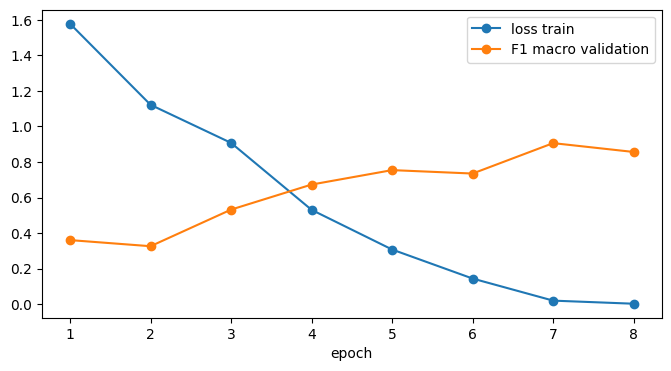

In [10]:
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

set_seed(SEED)
try:
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_CHECKPOINT, config=config, attn_implementation="sdpa")
except (ValueError, ImportError):
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_CHECKPOINT, config=config, attn_implementation="eager")
# le gradient checkpointing recalcule certaines activations au lieu de les garder : moins de mémoire
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f} M paramètres | attention : {model.config._attn_implementation}")


def val_score(model):
    probs = predict_probs(model, val_records, EVAL_BS)
    return scores([r["label_id"] for r in val_records], probs.argmax(1))


if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
history, best_val_f1 = train_model(model, train_records, val_score)
train_time_s = time.perf_counter() - t0
peak_vram_train = vram_peak_gb()

print(f"\nEntraînement : {train_time_s / 60:.1f} min | VRAM max : {peak_vram_train} Go")
print(f"Meilleur F1 macro en validation : {best_val_f1:.4f} (epoch {history['f1_macro'].idxmax() + 1})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["epoch"], history["loss_train"], marker="o", label="loss train")
ax.plot(history["epoch"], history["f1_macro"], marker="o", label="F1 macro validation")
ax.set_xlabel("epoch")
ax.legend()
plt.show()

## 7.5 Évaluation sur le test

ModernBERT long (mmBERT-base) :
Coefficient de Kappa : 0.8983
Niveau d'accord (Landis & Koch) : Presque parfait

Rapport de classification
               precision    recall  f1-score   support

Ancien fumeur       0.79      0.94      0.86        16
Fumeur actuel       0.87      0.72      0.79        18
Non mentionné       0.97      0.98      0.98        61
   Non-fumeur       1.00      0.96      0.98        25

     accuracy                           0.93       120
    macro avg       0.91      0.90      0.90       120
 weighted avg       0.94      0.93      0.93       120



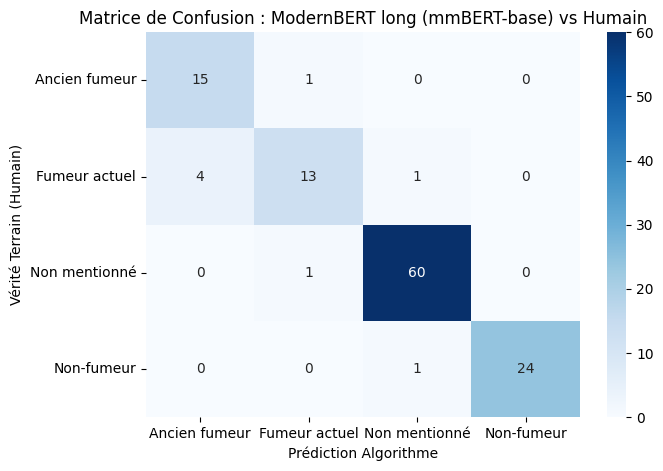




F1 macro : 0.9001 | Accuracy : 0.9333 | Précision : 0.9060 | Rappel : 0.9008
Inférence : 7.0 s | VRAM : 2.35 Go


In [11]:
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
probs = predict_probs(model, test_records, EVAL_BS)
infer_time_s = time.perf_counter() - t0
peak_vram_infer = vram_peak_gb()

y_true = df_test["label_id"].values
y_pred = probs.argmax(1)

pred_df = evaluate_and_save(
    f"ModernBERT long ({MODEL_CHECKPOINT.split('/')[-1]})", df_test["id"].values, y_true, y_pred, probs,
    extra_cols={"n_doc_tokens": [r["n_doc_tokens"] for r in test_records],
                "truncated": [r["truncated"] for r in test_records]},
    infos={"train_time_s": round(train_time_s, 1), "inference_time_s": round(infer_time_s, 2),
           "inference_ms_per_doc": round(1000 * infer_time_s / len(df_test), 1),
           "preprocessing_test_s": round(prep_test_s, 2),
           "peak_vram_train_gb": peak_vram_train, "peak_vram_infer_gb": peak_vram_infer,
           "best_val_f1_macro": round(best_val_f1, 4), "max_len": MAX_LEN, "n_truncated_docs_total": int(n_trunc),
           "config": {"model": MODEL_CHECKPOINT, "max_len": MAX_LEN, "epochs": EPOCHS, "lr": LR,
                      "train_bs": TRAIN_BS, "grad_acc": GRAD_ACC, "gradient_checkpointing": True,
                      "attn": model.config._attn_implementation, "seed": SEED,
                      "test_size": TEST_SIZE, "val_size": VAL_SIZE}},
)
print(f"Inférence : {infer_time_s:.1f} s | VRAM : {peak_vram_infer} Go")

### Résultats selon la longueur des documents

On compare les documents de plus de 512 tokens, que DrBERT ne peut pas lire en entier, aux documents plus courts.

In [12]:
an = pred_df.assign(correct=lambda d: d["y_true_id"] == d["y_pred_id"],
                    longueur=lambda d: np.where(d["n_doc_tokens"] > 512, "> 512 tokens", "<= 512 tokens"))
display(an.groupby("longueur")[["correct", "y_true_id", "y_pred_id"]].apply(lambda g: pd.Series({
    "n_docs": len(g), "accuracy": g["correct"].mean(),
    "f1_macro": f1_score(g["y_true_id"], g["y_pred_id"], average="macro", labels=range(NUM_LABELS), zero_division=0)})).round(3))

,n_docs,accuracy,f1_macro
longueur,,,
<= 512 tokens,37.0,1.000,0.500
> 512 tokens,83.0,0.904,0.892
